# Spesialis Fashion-MNIST: dua head dan dua loss
Jalankan sel dari atas ke bawah dengan Python, PyTorch, torchvision, NumPy, Matplotlib dan SciPy. Run pertama mengunduh Fashion-MNIST. Satu titik berarti satu kondisi model. X mengukur kesalahan head "kelas dia", Y mengukur kesalahan head "bukan dia". Keduanya dinilai pada semua gambar validasi.

In [1]:
# math menyediakan ceil dan log, random mengacak pergeseran dan urutan PCGrad, time mengukur durasi.
import math, random, time
# np mengolah array gambar dan label. torch menyediakan tensor, perangkat komputasi, dan gradien.
import numpy as np
import torch
# nn menyediakan lapisan jaringan. F menyediakan operasi padding, fungsi loss, dan softmax.
import torch.nn as nn
import torch.nn.functional as F
# plt menggambar hasil. datasets memuat Fashion-MNIST dan models menyediakan arsitektur ResNet.
import matplotlib.pyplot as plt
from torchvision import datasets, models

In [2]:
from copy import deepcopy
from collections import deque
from scipy.sparse.linalg import LinearOperator, minres
import inspect

In [3]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Perangkat:', dev)

Perangkat: cuda


In [4]:
# Angka ini boleh diubah sebelum menjalankan eksperimen.
CFG = dict(SEED=0, CLASS=5, BS=128, LR=0.001, EPOCHS=4, N_SPEC_HARD=2000,
           STEPS=60, ROUNDS=8, TARGET=0.15, WIDTH=0.02, PATIENCE=3,
           ALPHA_WINDOW=8, SECONDS=180, MINRES_ITERS=24, DAMP=0.1, STEP_SIZE=0.05)

In [5]:
# set_seed menerima s dari SEED (ditambah indeks kelas untuk spesialis). Fungsi mengatur generator
# acak Python, NumPy dan PyTorch tanpa nilai balik.
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

## Data spesialis
Data latih mencakup gambar tunggal serta potongan pakaian dari tumpukan. Validasi memilih model. Data uji hanya dipakai setelah pilihan selesai.

In [6]:
# CANVAS dan DS adalah ukuran sisi kanvas dan pakaian dalam piksel untuk penempatan, crop, padding,
# dan prep.
CANVAS, DS = 56, 28           # kanvas diperluas (sebelumnya 36), digit tetap 28x28 asli
# MAX_OVERLAP menjadi sasaran batas tumpang tindih saat mencari posisi di make_multi_flexible.
MAX_OVERLAP = 0.25            # maks. overlap kotak antar pakaian (fraksi luas 28x28)
# K_MIN dan K_MAX menentukan rentang jumlah pakaian per kanvas. K_MAX juga menentukan banyak slot
# label dan posisi.
K_MIN, K_MAX = 2, 4
# CLASS_NAMES memetakan indeks label Fashion-MNIST ke nama untuk laporan dan judul grafik.
CLASS_NAMES = ('T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot')

In [7]:
# fashion_tr dan fashion_te adalah dataset asli dari torchvision. Atribut data dan targets dibaca di
# bawah.
fashion_tr = datasets.FashionMNIST('./data', train=True, download=True)
fashion_te = datasets.FashionMNIST('./data', train=False, download=True)
# all_tr_x/all_tr_y menyimpan gambar/label untuk pembagian latih-validasi. fa_te_x/fa_te_y untuk
# tumpukan dan evaluasi uji.
all_tr_x, all_tr_y = fashion_tr.data.numpy(), fashion_tr.targets.numpy()
fa_te_x, fa_te_y = fashion_te.data.numpy(), fashion_te.targets.numpy()

In [8]:
# perm adalah urutan indeks acak dari SEED. Indeks yang sama menjaga pasangan gambar dan label saat
# dibagi.
perm = np.random.RandomState(CFG['SEED']).permutation(len(all_tr_x))
# fa_tr_x/fa_tr_y berisi 54.000 pasangan latih untuk gambar tunggal dan pembuatan tumpukan.
fa_tr_x, fa_tr_y = all_tr_x[perm[:54000]], all_tr_y[perm[:54000]]
# fa_val_x/fa_val_y adalah sisa pasangan dari perm untuk membuat tumpukan validasi.
fa_val_x, fa_val_y = all_tr_x[perm[54000:]], all_tr_y[perm[54000:]]

In [9]:
# make_multi_flexible membuat n kanvas dari imgs dan labels milik bagian data yang dipilih pemanggil.
# k_min/k_max membatasi jumlah item, seed mengatur undian, max_overlap dan n_tries mengatur pencarian
# posisi.
# Hasilnya tiga array NumPy berurutan (gambar, ID kelas per slot, koordinat per slot), diterima
# keluarga Xg/Yg/Pg atau Xh_raw/Yh_raw/Ph_raw.
def make_multi_flexible(imgs, labels, n, k_min=K_MIN, k_max=K_MAX, seed=1,
                        max_overlap=MAX_OVERLAP, n_tries=30):
    # rng adalah generator lokal dari seed untuk mengundi jumlah, indeks, dan posisi pakaian.
    rng = np.random.RandomState(seed)
    # X menyimpan piksel tiap kanvas. Y menyimpan ID kelas dan P menyimpan (baris, kolom) tiap slot.
    # -1 menandai slot kosong.
    X = np.zeros((n, CANVAS, CANVAS), dtype=np.uint8)
    Y = np.full((n, k_max), -1, dtype=np.int64)
    P = np.full((n, k_max, 2), -1, dtype=np.int64)
    # off adalah koordinat awal terbesar agar pakaian tetap muat di kanvas.
    off = CANVAS - DS
    # i memilih kanvas keluaran. k_items adalah jumlah pakaian yang diundi untuk kanvas itu.
    for i in range(n):
        k_items = rng.randint(k_min, k_max + 1)
        # idx berisi indeks sumber dari imgs/labels. boxes mengingat posisi yang sudah ditempati pada
        # kanvas i.
        idx = rng.randint(0, len(imgs), size=k_items)
        boxes = []
        # k adalah nomor slot keluaran, j indeks gambar asli dari idx untuk mengisi slot k.
        for k, j in enumerate(idx):
            # best dan best_ov menyimpan posisi dengan overlap terkecil beserta nilainya selama
            # pencarian.
            best, best_ov = None, 9.0
            # _ menghitung percobaan sampai n_tries. py dan px adalah calon baris dan kolom kiri atas.
            for _ in range(n_tries):          # cari posisi dengan overlap kecil
                py, px = rng.randint(0, off + 1), rng.randint(0, off + 1)
                # by dan bx berasal dari boxes. ov adalah fraksi overlap terbesar calon posisi
                # terhadap pakaian sebelumnya.
                ov = max([max(0, DS - abs(py - by)) * max(0, DS - abs(px - bx)) / (DS * DS)
                          for by, bx in boxes], default=0.0)
                if ov < best_ov:
                    best, best_ov = (py, px), ov
                if ov <= max_overlap:
                    break
            # py dan px mengambil posisi terbaik yang ditemukan, termasuk bila batas overlap belum
            # tercapai.
            py, px = best
            boxes.append((py, px))
            # patch menjumlahkan piksel lama dan imgs[j] dalam 16 bit. Hasil dibatasi ke 255 untuk X,
            # lalu label dan posisi dicatat.
            patch = X[i, py:py+DS, px:px+DS].astype(np.uint16) + imgs[j].astype(np.uint16)
            X[i, py:py+DS, px:px+DS] = np.minimum(patch, 255).astype(np.uint8)
            Y[i, k] = labels[j]
            P[i, k] = [py, px]
    return X, Y, P

In [10]:
# crop_pad menerima kanvas X, posisi P, dan nomor slot k dari pembuat data spesialis atau
# teacher_presence.
# Hasilnya array seukuran X berisi crop slot k di tengah kanvas hitam. Slot kosong menghasilkan kanvas
# hitam.
def crop_pad(X, P, k):
    # out menampung hasil crop. o adalah offset untuk menempatkannya di tengah.
    out = np.zeros_like(X)
    o = (CANVAS - DS) // 2
    # i memilih kanvas. y dan x berasal dari P[i,k] untuk menentukan area piksel sumber.
    for i in range(len(X)):
        if P[i, k, 0] != -1:
            y, x = P[i, k]
            out[i, o:o+DS, o:o+DS] = X[i, y:y+DS, x:x+DS]
    return out

In [11]:
# pad_fashion menerima imgs dari fa_tr_x atau fa_te_x dan mengembalikan kanvas terpusat untuk Xs atau
# Xte_single.
def pad_fashion(imgs):
    # out adalah kanvas kosong per gambar, o adalah offset tempat menyalin imgs ke tengah.
    out = np.zeros((len(imgs), CANVAS, CANVAS), np.uint8)
    o = (CANVAS - DS) // 2
    out[:, o:o+DS, o:o+DS] = imgs
    return out

In [12]:
# Data spesialis: gambar tunggal bersih + crop dari tumpukan, semuanya berlabel ASLI
# n_h menghitung jumlah kanvas sumber crop dari batas N_SPEC_HARD dan jumlah slot maksimum.
n_h = (CFG['N_SPEC_HARD'] + K_MAX - 1) // K_MAX
# Xh_raw/Yh_raw/Ph_raw adalah kanvas, kelas, dan posisi sintetis dari data latih untuk membuat contoh
# spesialis.
Xh_raw, Yh_raw, Ph_raw = make_multi_flexible(fa_tr_x, fa_tr_y, n_h, seed=4)
# Xs_h/Ys_h mula-mula daftar kumpulan crop/label per slot. k memilih slot, v menandai gambar yang
# memiliki slot itu.
Xs_h, Ys_h = [], []
for k in range(K_MAX):
    v = Ph_raw[:, k, 0] != -1
    Xs_h.append(crop_pad(Xh_raw, Ph_raw, k)[v]); Ys_h.append(Yh_raw[v, k])
# Xs_h dan Ys_h kemudian menjadi array crop dan label yang digabung, dipotong sesuai batas, lalu
# dipasangkan dengan data bersih.
Xs_h = np.concatenate(Xs_h)[:CFG['N_SPEC_HARD']]
Ys_h = np.concatenate(Ys_h)[:CFG['N_SPEC_HARD']]
# Xs memasangkan kanvas bersih dan crop dalam satu array gambar. Ys menyusun label asli dalam urutan
# yang sama.
Xs = np.concatenate([pad_fashion(fa_tr_x), Xs_h])
Ys = np.concatenate([fa_tr_y, Ys_h])

In [13]:
# Tensor disimpan di CPU. Hanya batch yang sedang diproses dipindahkan ke dev.
train = torch.from_numpy(Xs), torch.from_numpy(Ys)
valid = torch.from_numpy(pad_fashion(fa_val_x)), torch.from_numpy(fa_val_y)
test = torch.from_numpy(pad_fashion(fa_te_x)), torch.from_numpy(fa_te_y)
print('Spesialis:', CLASS_NAMES[CFG['CLASS']], '| gambar latih:', len(Ys))

Spesialis: Sandal | gambar latih: 55476


In [14]:
# 1 fungsiprep() menyiapkan gambar sebelum dimasukkan ke model. 
# 1 Gambar diubah ke format yang bisa dibaca model, lalu bisa digeser sedikit secara acak.
# 2 xb atau x-batch adalah sekumpulan gambar dalam bentuk tensor. 
# 2 Pada notebook ini, ukurannya (jumlah gambar, 56, 56). Setiap piksel biasanya bernilai dari 0 sampai 255.
# 3 shift adalah batas pergeseran acak dalam satuan piksel. Nilai awalnya 0, yang berarti gambar tidak digeser.   
# 4 Outputnya adalah tensor x yang siap masuk ke model. Ukurannya menjadi (jumlah gambar, 1, 56, 56). 
# 4 Angka 1 menunjukkan satu kanal warna karena gambar berwarna abu-abu. Nilai pikselnya sudah berada dalam rentang 0 sampai 1.
def prep(xb, shift=0): 
    # x berasal dari xb, dikonversi ke .float(), bagi .div(255), .unsqueeze(1) menambahkan dimensi kanal pada posisi ke-1
    x = xb.float().div(255).unsqueeze(1)
    if shift: 
        # sy dan sx adalah pergeseran acak vertikal/horizontal untuk seluruh batch. x dipad lalu dipotong kembali seukuran CANVAS.
        sy, sx = random.randint(-shift, shift), random.randint(-shift, shift) # cari int buat digeser
        x = F.pad(x, (shift,)*4) # padding biar ga kepotong pas digeser
        x = x[:, :, shift+sy:shift+sy+CANVAS, shift+sx:shift+sx+CANVAS] # baru deh dipotong
    return x # satu x-batch yang sudah digeser random sejauh shift

## Model dan aturan belajar
Backbone membaca gambar satu kali. Dua head masing-masing belajar menjawab satu pertanyaan ya/tidak. Kita memakai jaringan kecil dengan aktivasi halus agar turunan kedua untuk MINRES dapat dihitung pada CPU maupun GPU.

In [15]:
class Specialist(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = nn.Sequential(nn.AvgPool2d(2), nn.Conv2d(1, 8, 5, stride=2),
                                      nn.Softplus(), nn.AvgPool2d(2), nn.Flatten(),
                                      nn.Linear(8 * 6 * 6, 32), nn.Softplus())
        self.heads = nn.ModuleList([nn.Linear(32, 1), nn.Linear(32, 1)])

    def forward(self, x):
        features = self.backbone(x)
        return torch.cat([head(features) for head in self.heads], dim=1)

In [16]:
def head_losses(model, batch):
    # Kolom pertama berlabel 1 untuk sandal (jika CLASS=5), kolom kedua untuk selain sandal.
    images, labels = batch
    if labels.ndim == 2:
        # Target generalis berbentuk (gambar, kelas). Rata-ratakan tiap jenis jawaban.
        present = labels.to(dev)
        targets = torch.stack([present, 1 - present], dim=2)
        scores = model(prep(images.to(dev)))
        return F.binary_cross_entropy_with_logits(scores, targets, reduction='none').mean((0, 1))
    positive = labels.to(dev) == CFG['CLASS']
    targets = torch.stack([positive, ~positive], dim=1).float()
    scores = model(prep(images.to(dev)))
    return F.binary_cross_entropy_with_logits(scores, targets, reduction='none').mean(0)

In [17]:
@torch.no_grad()
def evaluate(model, data):
    # Hitung rata-rata per gambar, termasuk bila batch terakhir lebih kecil.
    model.eval()
    total = torch.zeros(2, device=dev)
    for images, labels in zip(*(v.split(CFG['BS']) for v in data)):
        total += len(labels) * head_losses(model, (images, labels))
    return (total / len(data[1])).cpu().numpy()

In [18]:
# flat_grads menerima daftar losses dari loss_fn dan params dari backbone bersama. 
# Hasil G punya satu baris gradien per tugas.
def flat_grads(losses, params):
    # gs mengumpulkan baris. l adalah satu loss, g adalah tuple gradien l terhadap params.
    gs = []
    for l in losses:
        g = torch.autograd.grad(l, params, retain_graph=True, allow_unused=True)
        # gi dipasangkan dengan parameter p. Gradien yang kosong diisi nol sebelum semua komponen
        # diratakan dan digabung.
        gs.append(torch.cat([(gi if gi is not None else torch.zeros_like(p)).flatten() for gi, p in zip(g, params)]))
    return torch.stack(gs)

In [19]:
# pcgrad menerima matriks gradien G dari flat_grads. Hasilnya vektor jumlah gradien setelah proyeksi,
# untuk g di train_step.
def pcgrad(G):
    # T adalah jumlah baris G. out menyalin G agar tiap baris dapat diperbarui.
    T = len(G); out = G.clone()
    # i memilih tugas yang dikoreksi, j memilih tugas pembanding secara acak.
    for i in range(T):
        for j in random.sample(range(T), T):
            if j == i: continue
            # dot mengukur keselarasan out[i] dan G[j]. Nilai negatif memicu pengurangan komponen yang
            # bertentangan.
            dot = (out[i] * G[j]).sum()
            if dot < 0:
                out[i] = out[i] - dot / (G[j].norm() ** 2 + 1e-12) * G[j]
    return out.sum(0)

In [20]:
# mgda_weights menerima G dari flat_grads dan batas iterasi iters. Hasilnya bobot a untuk kombinasi
# gradien a @ G.
def mgda_weights(G, iters=50):
    # M berisi hasil kali dalam antargradien. T jumlah tugas untuk menentukan ukuran a.
    M = G @ G.T; T = len(G)
    # a dimulai dengan bobot seragam, lalu diperbarui untuk memperkecil norma gradien gabungan.
    a = torch.ones(T, device=G.device) / T
    # _ menghitung iterasi. i memilih komponen terkecil dari M @ a sebagai arah menuju satu tugas.
    for _ in range(iters):
        i = torch.argmin(M @ a)
        # e memberi bobot satu pada tugas i. d adalah perubahan dari a menuju e, gamma menentukan
        # panjang langkah sepanjang d.
        e = torch.zeros_like(a); e[i] = 1
        d = e - a
        gamma = torch.clamp(-(d @ M @ a) / (d @ M @ d + 1e-12), 0, 1)
        a = a + gamma * d
    return a

In [21]:
# FAMO menyimpan dan menyesuaikan bobot tugas selama pelatihan bila METHOD memilih famo.
class FAMO:
    # __init__ menerima self, jumlah tugas T dari train_step, lr untuk Adam internal dan gamma untuk
    # weight decay. Ia mengisi atribut instance.
    def __init__(self, T, lr=0.025, gamma=1e-3):
        # self.w adalah skor bobot yang dilatih. self.opt mengoptimalkan skor ini dan self.eps menjaga
        # log dan pembagian tetap terdefinisi.
        self.w = torch.zeros(T, device=dev, requires_grad=True)
        self.opt = torch.optim.Adam([self.w], lr=lr, weight_decay=gamma)
        self.eps = 1e-8
    # weighted menerima self dan tensor losses hasil stack loss tiap tugas. Hasilnya loss skalar untuk
    # backward di train_step.
    def weighted(self, losses):
        # D adalah losses ditambah eps, z adalah bobot tugas ternormalisasi dari self.w, c adalah
        # faktor normalisasi tanpa gradien.
        D = losses + self.eps
        z = F.softmax(self.w, -1)
        c = (z / D).sum().detach()
        return (D.log() * z / c).sum()
    # update menerima self, prev dan curr (loss per tugas sebelum dan sesudah langkah model). Ia
    # memperbarui self.w tanpa nilai balik.
    def update(self, prev, curr):
        # delta mengukur penurunan log-loss per tugas. d mengubah delta menjadi gradien untuk
        # self.w.grad yang dipakai self.opt.
        delta = (prev + self.eps).log() - (curr + self.eps).log()
        with torch.enable_grad():
            d = torch.autograd.grad(F.softmax(self.w, -1), self.w, grad_outputs=delta.detach())[0]
        self.opt.zero_grad(); self.w.grad = d; self.opt.step()

In [22]:
def train_step(model, optimizer, batch, method, famo=None, alpha=None):
    # Hanya backbone yang dipakai bersama. Setiap head juga mendapat gradien loss-nya.
    model.train()
    losses = head_losses(model, batch)
    optimizer.zero_grad()
    if method in ('MGDA', 'PCGrad'):
        shared = list(model.backbone.parameters())
        G = flat_grads(losses, shared)
        if method == 'MGDA':
            alpha = mgda_weights(G).detach()
            combined = alpha @ G
        else:
            combined = pcgrad(G) / 2
        losses.mean().backward()
        offset = 0
        for param in shared:
            size = param.numel()
            param.grad = combined[offset:offset+size].view_as(param).clone()
            offset += size
    elif method == 'FAMO':
        alpha = famo.w.detach().softmax(0)
        famo.weighted(losses).backward()
    else:
        # Alfa tetap untuk eksplorasi ulang dalam satu ronde pembagian dua.
        (alpha @ losses).backward()
    optimizer.step()
    if method == 'FAMO':
        with torch.no_grad():
            after = head_losses(model, batch)
        famo.update(losses.detach(), after)
    return None if alpha is None else alpha.detach().cpu().numpy()

In [23]:
def checkpoint(model, name, alpha=None, valid=valid):
    # Simpan salinan parameter serta dua loss validasi. Skor kecil berarti head terburuk pun baik.
    xy = evaluate(model, valid)
    return dict(name=name, xy=xy, score=float(max(xy)), alpha=alpha,
                state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})

In [24]:
def explore(initial, method, train=train, valid=valid):
    # Seed yang sama memberi setiap metode urutan batch yang sama.
    set_seed(CFG['SEED'])
    model = deepcopy(initial)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    famo = FAMO(2) if method == 'FAMO' else None
    history = []
    for epoch in range(CFG['EPOCHS']):
        recent = deque(maxlen=CFG['ALPHA_WINDOW'])
        for ids in torch.randperm(len(train[1])).split(CFG['BS']):
            alpha = train_step(model, optimizer, (train[0][ids], train[1][ids]), method, famo)
            if alpha is not None:
                recent.append(alpha)
        history.append(checkpoint(model, method, np.mean(recent, axis=0) if recent else None, valid))
    return history

In [25]:
set_seed(CFG['SEED'])
initial = Specialist().to(dev)
start = checkpoint(initial, 'Awal')
paths = {method: explore(initial, method) for method in ('PCGrad', 'MGDA', 'FAMO')}

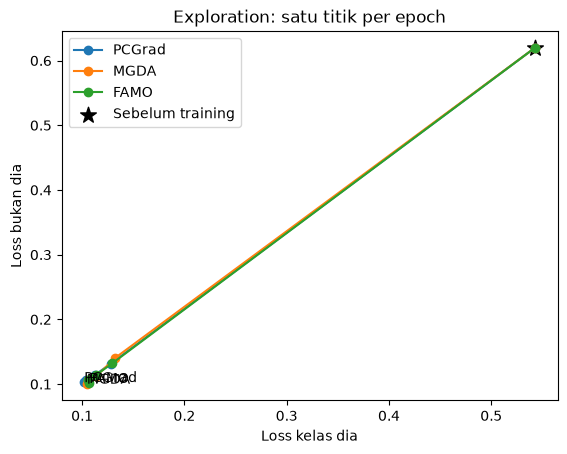

In [26]:
fig, ax = plt.subplots()
for method, points in paths.items():
    xy = np.array([p['xy'] for p in [start] + points])
    ax.plot(*xy.T, 'o-', label=method)
    ax.annotate(method, xy[-1])
ax.scatter(*start['xy'], marker='*', s=140, color='black', label='Sebelum training')
ax.set(xlabel='Loss kelas dia', ylabel='Loss bukan dia', title='Exploration: satu titik per epoch')
ax.legend()
plt.show()

In [27]:
def dominates(a, b):
    # A mengalahkan B bila kedua loss paling tidak sama baik, dan minimal satu lebih kecil.
    return np.all(a['xy'] <= b['xy']) and np.any(a['xy'] < b['xy'])

In [28]:
def choose_pair(points):
    # Cari tetangga pada batas kompromi. Pakai pasangan FAMO-MGDA dengan celah terbesar.
    front = [p for p in points if not any(dominates(q, p) for q in points)]
    eligible = sorted((p for p in front if p['name'] in ('FAMO','MGDA')), key=lambda p: p['xy'][0])
    pairs = [(a,b) for a,b in zip(eligible, eligible[1:]) if a['name'] != b['name']
             and a['xy'][0] < b['xy'][0] and a['xy'][1] > b['xy'][1]
             and abs(a['alpha'][0]-b['alpha'][0]) > CFG['WIDTH']]
    return max(pairs, key=lambda ab: np.linalg.norm(ab[0]['xy']-ab[1]['xy']), default=None)

In [29]:
pool = [p for history in paths.values() for p in history]
pair = choose_pair(pool)
print('Pasangan:', [p['name'] for p in pair] if pair else 'Belum ada dua ujung yang memenuhi syarat.')

Pasangan: Belum ada dua ujung yang memenuhi syarat.


## Expand setelah training
Kedua cabang memakai pasangan awal dan batas waktu yang sama. Target pilihan adalah mengecilkan loss terbesar di antara dua head. Alfa FAMO memakai softmax skor tugas dan alfa MGDA memakai koefisien gradien. Mencampur keduanya adalah hipotesis eksperimen. Pembagian dua mencari kandidat terbaik yang sempat diuji dan tidak menjamin optimum global.

In [30]:
def midpoint_candidate(model, left, right, round_id, rng, train=train, valid=valid):
    # Mulai dari ujung bergantian. Latih model pada alfa tengah selama beberapa batch.
    parent = (left, right)[round_id % 2]
    model.load_state_dict(parent['state'])
    alpha = (left['alpha'] + right['alpha']) / 2
    weight = torch.as_tensor(alpha, device=dev)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    for step in range(CFG['STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        train_step(model, optimizer, (train[0][ids], train[1][ids]), 'Alfa tengah', alpha=weight)
    return checkpoint(model, 'Alfa tengah', alpha, valid)

In [31]:
def minres_candidate(model, left, right, round_id, rng, train=train, valid=valid):
    # Dekati arah kompromi lokal: H d = -G^T perubahan_alfa.
    # H berasal dari loss berbobot pada satu batch tetap. Damping menstabilkan sistem.
    parent, other = (left, right) if round_id % 2 == 0 else (right, left)
    model.load_state_dict(parent['state'])
    model.eval()
    ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
    losses = head_losses(model, (train[0][ids], train[1][ids]))
    params = list(model.parameters())
    # Estimasi koefisien lokal dengan gradien seluruh parameter.
    G = flat_grads(losses, params).detach()
    alpha = mgda_weights(G).detach()
    desired = torch.as_tensor(other['alpha'], device=dev)
    rhs = (-(desired-alpha) @ G).cpu().double().numpy()
    gradient = torch.cat([g.flatten() for g in torch.autograd.grad(alpha @ losses, params, create_graph=True)])
    # SciPy cukup meminta hasil H kali v. Matriks Hessian penuh tidak perlu disimpan.
    def multiply(vector):
        v = torch.as_tensor(vector, dtype=gradient.dtype, device=dev)
        hv = torch.autograd.grad(gradient, params, grad_outputs=v, retain_graph=True)
        result = torch.cat([h.flatten() for h in hv]) + CFG['DAMP'] * v
        return result.detach().cpu().double().numpy()
    operator = LinearOperator((len(rhs), len(rhs)), matvec=multiply, dtype=np.float64)
    tolerance = 'rtol' if 'rtol' in inspect.signature(minres).parameters else 'tol'
    direction, info = minres(operator, rhs, maxiter=CFG['MINRES_ITERS'], **{tolerance: 1e-3})
    residual = np.linalg.norm(multiply(direction)-rhs) / max(np.linalg.norm(rhs), 1e-12)
    print('MINRES status:', info, '| residu relatif:', round(residual, 4))
    if info < 0 or not np.isfinite(residual) or residual >= 1 or np.linalg.norm(direction) < 1e-12:
        return None
    # Batasi panjang langkah. Titik hasil langkah ini masih kandidat yang perlu dievaluasi.
    delta = torch.as_tensor(direction, device=dev, dtype=gradient.dtype)
    delta *= CFG['STEP_SIZE'] / delta.norm().clamp(min=CFG['STEP_SIZE'])
    offset = 0
    with torch.no_grad():
        for param in params:
            param.add_(delta[offset:offset+param.numel()].view_as(param))
            offset += param.numel()
    return checkpoint(model, 'MINRES', ((alpha + desired) / 2).cpu().numpy(), valid)

In [32]:
def run_expand(pair, generate, initial, pool, train=train, valid=valid):
    # Batas waktu diperiksa antar-ronde agar langkah yang sudah dimulai selesai utuh.
    if pair is None:
        return [], 0., 'Tidak ada pasangan'
    left, right = pair
    model = deepcopy(initial)
    rng = torch.Generator().manual_seed(CFG['SEED'] + 1)
    points = []
    best = min(p['score'] for p in pool)
    stale = 0
    reason = 'Batas ronde'
    begin = time.perf_counter()
    for r in range(CFG['ROUNDS']):
        if best <= CFG['TARGET'] or stale >= CFG['PATIENCE']:
            reason = 'Target tercapai' if best <= CFG['TARGET'] else 'Skor belum membaik'
            break
        if time.perf_counter()-begin >= CFG['SECONDS']:
            reason = 'Batas waktu'
            break
        if generate is midpoint_candidate and abs(left['alpha'][0]-right['alpha'][0]) <= CFG['WIDTH']:
            reason = 'Interval alfa kecil'
            break
        new = generate(model, left, right, r, rng, train, valid)
        if new is None:
            reason = 'Langkah numerik gagal'
            break
        points.append(new)
        stale = 0 if new['score'] < best else stale+1
        best = min(best, new['score'])
        if left['score'] <= right['score']:
            right = new
        else:
            left = new
    return points, time.perf_counter()-begin, reason

In [33]:
results = {'Tanpa expand': ([], 0., 'Baseline'),
           'MINRES': run_expand(pair, minres_candidate, initial, pool),
           'Alfa tengah': run_expand(pair, midpoint_candidate, initial, pool)}

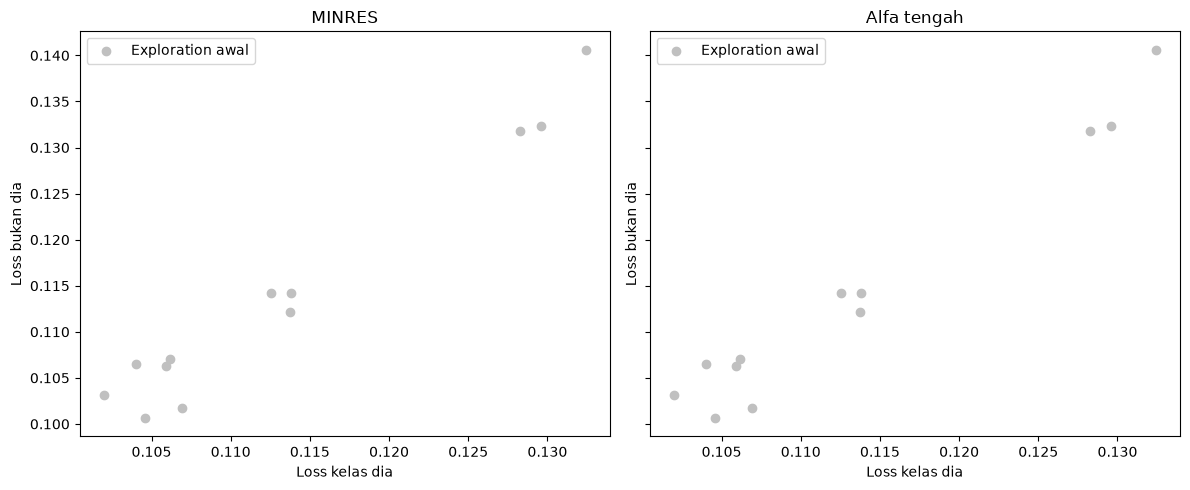

In [34]:
fig, panels = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(panels, ('MINRES', 'Alfa tengah')):
    ax.scatter(*np.array([p['xy'] for p in pool]).T, color='silver', label='Exploration awal')
    for label, point in zip(('A', 'B'), pair or ()):
        ax.scatter(*point['xy'], marker='s')
        ax.annotate(label, point['xy'])
    for r, point in enumerate(results[name][0], 1):
        ax.scatter(*point['xy'], color='darkgreen')
        label = str(r) if name == 'MINRES' else f"{r}: a={point['alpha'][0]:.2f}"
        ax.annotate(label, point['xy'])
    ax.set(title=name, xlabel='Loss kelas dia', ylabel='Loss bukan dia')
    ax.legend()
plt.tight_layout()
plt.show()

In [35]:
# Pilih model memakai validasi saja. Tampilkan dua loss uji setelah pemilihan selesai.
print('Kondisi | ronde | detik expand | validasi X,Y | skor validasi | uji X,Y | alasan berhenti')
for name, (extra, seconds, reason) in results.items():
    winner = min(pool + extra, key=lambda p: p['score'])
    model = deepcopy(initial)
    model.load_state_dict(winner['state'])
    print(name, len(extra), round(seconds, 2), winner['xy'].round(4),
          round(winner['score'], 4), evaluate(model, test).round(4), reason, sep=' | ')

Kondisi | ronde | detik expand | validasi X,Y | skor validasi | uji X,Y | alasan berhenti
Tanpa expand | 0 | 0.0 | [0.102  0.1031] | 0.1031 | [0.1015 0.1029] | Baseline
MINRES | 0 | 0.0 | [0.102  0.1031] | 0.1031 | [0.1015 0.1029] | Tidak ada pasangan
Alfa tengah | 0 | 0.0 | [0.102  0.1031] | 0.1031 | [0.1015 0.1029] | Tidak ada pasangan


## Generalis: satu model untuk seluruh kelas
Setiap kelas punya dua keluaran: hadir dan tidak hadir. X adalah rata-rata loss hadir untuk sepuluh kelas, Y rata-rata loss tidak hadir. Kedua tujuan inilah yang diseimbangkan PCGrad, MGDA, dan FAMO. Generalis melihat gambar tumpukan utuh. Sepuluh guru memberikan target lunak dari potongan pakaian saat pelatihan. Validasi dan uji mengukur kesalahan terhadap label asli.

In [36]:
class Generalist(Specialist):
    def __init__(self):
        super().__init__()
        # Satu backbone bersama; tiap lapisan menghasilkan dua skor untuk satu kelas.
        self.heads = nn.ModuleList(nn.Linear(32, 2) for _ in CLASS_NAMES)

    def forward(self, x):
        features = self.backbone(x)
        return torch.stack([head(features) for head in self.heads], dim=1)

In [37]:
def train_teacher(class_id):
    # Guru ini belajar dari label asli. Satu guru hanya menjawab untuk class_id.
    set_seed(CFG['SEED'] + class_id)
    teacher = Specialist().to(dev)
    optimizer = torch.optim.AdamW(teacher.parameters(), lr=CFG['LR'])
    for epoch in range(CFG['EPOCHS']):
        for ids in torch.randperm(len(train[1])).split(CFG['BS']):
            yes = train[1][ids].to(dev) == class_id
            target = torch.stack([yes, ~yes], dim=1).float()
            scores = teacher(prep(train[0][ids].to(dev)))
            optimizer.zero_grad()
            F.binary_cross_entropy_with_logits(scores, target).backward()
            optimizer.step()
    return teacher.eval()

In [38]:
# Gunakan kembali spesialis terpilih; latih guru lain untuk sembilan kelas sisanya.
teacher_candidates = pool + [p for extra, _, _ in results.values() for p in extra]
selected_teacher = min(teacher_candidates, key=lambda p: p['score'])
teachers = []
for class_id in range(len(CLASS_NAMES)):
    if class_id == CFG['CLASS']:
        teacher = deepcopy(initial)
        teacher.load_state_dict(selected_teacher['state'])
        teacher.eval()
    else:
        teacher = train_teacher(class_id)
    teachers.append(teacher)

In [39]:
@torch.no_grad()
def teacher_targets(images, positions, teachers):
    # Satu guru menilai setiap crop yang terisi. Ambil peluang tertinggi antar-crop.
    target = torch.zeros(len(images), len(teachers))
    for slot in range(positions.shape[1]):
        rows = np.flatnonzero(positions[:, slot, 0] >= 0)
        crops = crop_pad(images, positions, slot)
        for start_row in range(0, len(rows), CFG['BS']):
            ids = rows[start_row:start_row + CFG['BS']]
            x = prep(torch.from_numpy(crops[ids]).to(dev))
            prob = torch.stack([t(x)[:, 0].sigmoid() for t in teachers], dim=1).cpu()
            target[ids] = torch.maximum(target[ids], prob)
    return target

In [40]:
def generalist_data(images, labels, size, seed, teachers=None):
    # ID kelas tiap slot menjadi label hadir/tidak untuk evaluasi. Guru memberikan target latih.
    canvas, slots, positions = make_multi_flexible(images, labels, size, seed=seed)
    if teachers is None:
        target = torch.stack([torch.from_numpy((slots == c).any(axis=1))
                              for c in range(len(CLASS_NAMES))], dim=1).float()
    else:
        target = teacher_targets(canvas, positions, teachers)
    return torch.from_numpy(canvas), target

In [41]:
gen_train = generalist_data(fa_tr_x, fa_tr_y, 20000, 1, teachers)
gen_valid = generalist_data(fa_val_x, fa_val_y, 2000, 2)
gen_test = generalist_data(fa_te_x, fa_te_y, 5000, 3)

In [42]:
# Tiga metode mulai dari salinan generalis yang persis sama.
set_seed(CFG['SEED'])
gen_initial = Generalist().to(dev)
gen_start = checkpoint(gen_initial, 'Awal', valid=gen_valid)
gen_paths = {m: explore(gen_initial, m, gen_train, gen_valid) for m in ('PCGrad', 'MGDA', 'FAMO')}

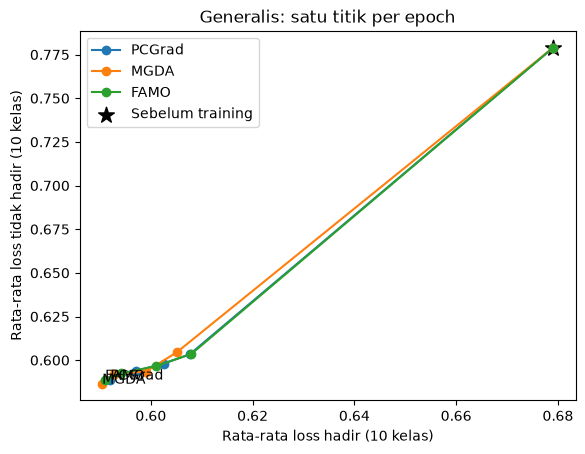

In [43]:
fig, ax = plt.subplots()
for method, points in gen_paths.items():
    xy = np.array([p['xy'] for p in [gen_start] + points])
    ax.plot(*xy.T, 'o-', label=method)
    ax.annotate(method, xy[-1])
ax.scatter(*gen_start['xy'], marker='*', s=140, color='black', label='Sebelum training')
ax.set(xlabel='Rata-rata loss hadir (10 kelas)', ylabel='Rata-rata loss tidak hadir (10 kelas)', title='Generalis: satu titik per epoch')
ax.legend()
plt.show()

In [44]:
gen_pool = [p for path in gen_paths.values() for p in path]
gen_pair = choose_pair(gen_pool)
print('Pasangan generalis:', [p['name'] for p in gen_pair] if gen_pair else 'Tidak ada pasangan yang memenuhi syarat')

Pasangan generalis: Tidak ada pasangan yang memenuhi syarat


In [45]:
gen_results = {'Tanpa expand': ([], 0., 'Baseline')}
for name, generate in [('MINRES', minres_candidate), ('Alfa tengah', midpoint_candidate)]:
    gen_results[name] = run_expand(gen_pair, generate, gen_initial, gen_pool, gen_train, gen_valid)

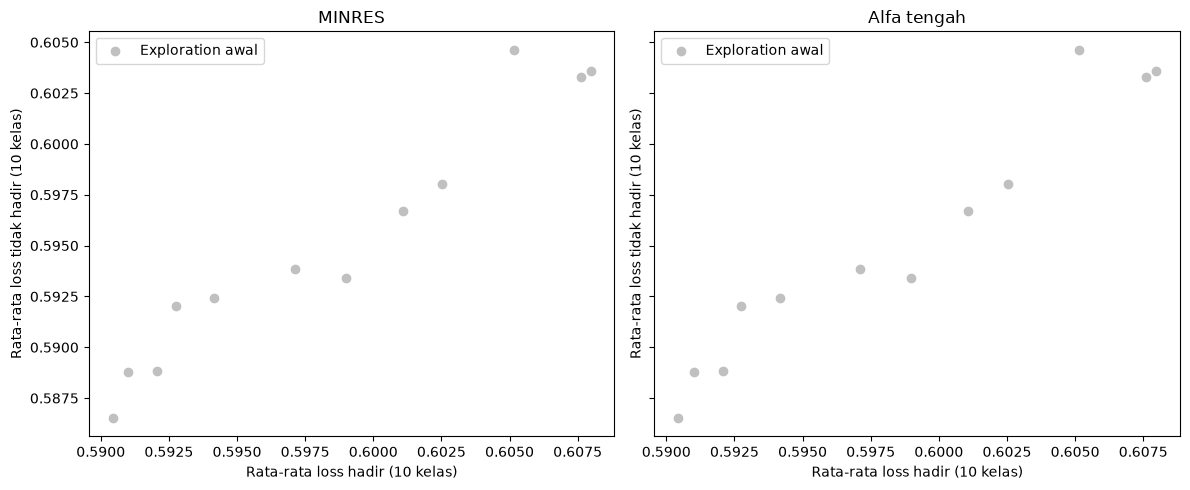

In [46]:
fig, panels = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(panels, ('MINRES', 'Alfa tengah')):
    ax.scatter(*np.array([p['xy'] for p in gen_pool]).T, color='silver', label='Exploration awal')
    for label, point in zip(('A', 'B'), gen_pair or ()):
        ax.scatter(*point['xy'], marker='s')
        ax.annotate(label, point['xy'])
    for r, point in enumerate(gen_results[name][0], 1):
        ax.scatter(*point['xy'], color='darkgreen')
        label = str(r) if name == 'MINRES' else f"{r}: a={point['alpha'][0]:.2f}"
        ax.annotate(label, point['xy'])
    ax.set(title=name, xlabel='Rata-rata loss hadir (10 kelas)', ylabel='Rata-rata loss tidak hadir (10 kelas)')
    ax.legend()
plt.tight_layout()
plt.show()

In [47]:
# Pilih model memakai validasi saja. Tampilkan dua loss uji setelah pemilihan selesai.
print('Kondisi | ronde | detik expand | validasi X,Y | skor validasi | uji X,Y | alasan berhenti')
for name, (extra, seconds, reason) in gen_results.items():
    winner = min(gen_pool + extra, key=lambda p: p['score'])
    model = deepcopy(gen_initial)
    model.load_state_dict(winner['state'])
    print(name, len(extra), round(seconds, 2), winner['xy'].round(4),
          round(winner['score'], 4), evaluate(model, gen_test).round(4), reason, sep=' | ')

Kondisi | ronde | detik expand | validasi X,Y | skor validasi | uji X,Y | alasan berhenti
Tanpa expand | 0 | 0.0 | [0.5904 0.5865] | 0.5904 | [0.5871 0.5838] | Baseline
MINRES | 0 | 0.0 | [0.5904 0.5865] | 0.5904 | [0.5871 0.5838] | Tidak ada pasangan
Alfa tengah | 0 | 0.0 | [0.5904 0.5865] | 0.5904 | [0.5871 0.5838] | Tidak ada pasangan
